# OlmoEarth: annual Sentinel-1/2 embeddings with native `predict_onnx`

This notebook uses a year of Sentinel-1 and Sentinel-2 data to make a map of OlmoEarth features for **Mol, Belgium, in 2024**. Each 40 m pixel holds a feature vector rather than a land-cover label. These vectors can serve as inputs for classification, clustering or similarity analysis. The PCA plots below show how they vary across the area.

The default is **Nano**, which returns 128 bands. The saved plots below are from this model. Tiny, Small and Base return 192, 384 and 768 bands.

```text
S2 + SCL cloud mask → monthly median ─┐
                                     ├→ 12 × 17 packed bands → predict_onnx → annual D-band cube
S1 VV/VH → linear monthly mean → dB ─┘                                      ↓
                                                                    GeoTIFF + PCA
```

Within each 320 m tile, the model combines information from all months and both sensors. Averaging the valid features gives one vector per patch for the year. This uses the pretrained model without retraining or a UDF.

The notebook runs on CDSE using its experimental `predict_onnx` process with a STAC model description. Read the [model's restricted-use license](./README.md#licensing) before using or sharing the model or anything derived from it.


## About OlmoEarth

[OlmoEarth](https://github.com/allenai/olmoearth_pretrain) is a family of Earth-observation models from Ai2. The models use observations from different dates and support Sentinel-1, Sentinel-2 and Landsat. This example uses the two Sentinel sensors. Nano is the smallest model in the family, so it's the default for this CPU example. The [README](./README.md#about-olmoearth) lists the other variants and links to the report.

The pretrained weights remain unchanged. The openEO input layout and annual averaging are additions for this example, not an official annual-output model trained by Ai2. Switching variants requires retraining any classifier or other model built on the features.


## 1. Prepare the environment and model

Start with the [quick start](./README.md#quick-start). Install `requirements-export.txt`, then run `export_olmoearth_to_onnx.py --variant nano` and `check_olmoearth_onnx.py --variant nano` locally. Run these scripts once per variant; they aren't UDFs.

After that, the notebook only needs `requirements.txt`, not PyTorch. Start Jupyter in this directory, with the ONNX file and its matching STAC JSON beside the notebook.

`openeo_olmoearth.py` holds band names, dates and model checks shared with the export scripts. The satellite processing code is in the cells below.


In [1]:
from pathlib import Path
from datetime import date
import json

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from matplotlib.ticker import MultipleLocator
from openeo.rest.connection import connect
from openeo.rest.multiresult import MultiResult
from openeo.extra.artifacts.artifact_helper import build_artifact_helper
from openeo.processes import if_, is_nan, log
from openeo_olmoearth import (
    S2_BANDS, INPUT_BANDS, model_name, calendar_months,
    validate_contract, validate_model,
)

ROOT = Path.cwd()
if not (ROOT / 'openeo_olmoearth.py').is_file():
    raise FileNotFoundError('Start Jupyter from the olmoearth example directory')


## 2. Choose the model variant, area and year

For a first run, keep the defaults: a 2.56 × 2.56 km area near VITO in Mol, in 2024. To try another model, export it first and set `VARIANT` to `tiny`, `small` or `base`. They all use 32×32 input tiles and return features at 40 m, but the larger models need more memory and compute. The [README](./README.md#checks-and-limitations) lists the tested cases.

Leave `JOB_ID = None` to submit a new job. To return to a job later, paste its printed ID here. Clear it when changing the model, area or year. The monthly inputs are saved for plotting; the model doesn't need a separate input file.


In [2]:
VARIANT = 'nano'
BACKEND = 'https://openeo.dataspace.copernicus.eu'
YEAR = 2024
EXTENT = {'west': 644930, 'south': 5674970, 'east': 647490, 'north': 5677530, 'crs': 32631}
JOB_ID = None  # Set your own existing job identifier to resume instead of submitting again.
JOB_OPTIONS = {
    'driver-memory': '4G', 'executor-memory': '6G',
    'executor-memoryOverhead': '2G', 'executor-cores': 1,
}

MODEL_PATH = ROOT / f'{model_name(VARIANT)}.onnx'
STAC_PATH = MODEL_PATH.with_suffix('.stac.json')

if not MODEL_PATH.is_file() or not STAC_PATH.is_file():
    raise FileNotFoundError('Run the local exporter and checker for this variant first')


## 3. Connect and authenticate

A CDSE account with openEO access is required. OIDC prompts for sign-in on the first run; later runs can usually reuse that login. Don't paste tokens into the notebook. This cell also checks the required backend processes. Check process support before using a different backend.


In [3]:
connection = connect(BACKEND).authenticate_oidc()
required = {
    'aggregate_temporal', 'predict_onnx', 'sar_backscatter', 'to_scl_dilation_mask',
    'convert_data_type', 'resample_cube_spatial',
}
available = {p['id'] for p in connection.list_processes()}

if required - available:
    raise RuntimeError(f'Backend missing processes: {sorted(required - available)}')

print('Connected; required processes are advertised')


Authenticated using refresh token.


Connected; required processes are advertised


## 4. Define twelve calendar months

The calendar divides the year into months, including 29 February in a leap year. Each interval includes its start date but not its end date: `[start, end)`.

The model also needs a date for each monthly composite. Each composite gets the month's midpoint as `[day, zero-based month, year]`, not the date of a particular image. Month labels keep the inputs in order. If a month has no observations, leave it missing rather than borrowing data from the next one.


In [4]:
intervals, timestamps = calendar_months(YEAR)
month_labels = [interval[0] for interval in intervals]
temporal_extent = [intervals[0][0], intervals[-1][1]]

for interval, timestamp in zip(intervals, timestamps):
    print(interval, '→', timestamp)


['2024-01-01', '2024-02-01'] → [16, 0, 2024]
['2024-02-01', '2024-03-01'] → [15, 1, 2024]
['2024-03-01', '2024-04-01'] → [16, 2, 2024]
['2024-04-01', '2024-05-01'] → [16, 3, 2024]
['2024-05-01', '2024-06-01'] → [16, 4, 2024]
['2024-06-01', '2024-07-01'] → [16, 5, 2024]
['2024-07-01', '2024-08-01'] → [16, 6, 2024]
['2024-08-01', '2024-09-01'] → [16, 7, 2024]
['2024-09-01', '2024-10-01'] → [16, 8, 2024]
['2024-10-01', '2024-11-01'] → [16, 9, 2024]
['2024-11-01', '2024-12-01'] → [16, 10, 2024]
['2024-12-01', '2025-01-01'] → [16, 11, 2024]


## 5. Sentinel-2: mask first, then make monthly medians

OlmoEarth needs all twelve bands, including B01 and B09. Nearest-neighbour resampling puts them on a 10 m grid without adding detail to the coarser bands. The SCL erosion/dilation mask removes unwanted pixels over the same area before the monthly medians are calculated.

CDSE has already corrected the DN offsets. **Don't subtract another 1000 or divide by 10000.** No further normalization is needed: OlmoEarth's normalization is already in the ONNX model.


In [5]:
optical = connection.load_collection(
    'SENTINEL2_L2A', bands=S2_BANDS, spatial_extent=EXTENT,
    temporal_extent=temporal_extent, properties={'eo:cloud_cover': lambda x: x <= 60},
).resample_spatial(resolution=10, projection=EXTENT['crs'], method='near')

scl = connection.load_collection(
    'SENTINEL2_L2A', bands=['SCL'], spatial_extent=EXTENT,
    temporal_extent=temporal_extent, properties={'eo:cloud_cover': lambda x: x <= 60},
).resample_spatial(resolution=10, projection=EXTENT['crs'], method='near')

cloud_mask = scl.process(
    'to_scl_dilation_mask', data=scl, scl_band_name='SCL',
    erosion_kernel_size=3, kernel1_size=17, kernel2_size=77,
    mask1_values=[2, 4, 5, 6, 7], mask2_values=[3, 8, 9, 10, 11],
).resample_cube_spatial(optical).filter_bbox(**EXTENT)

s2 = optical.mask(cloud_mask).aggregate_temporal(
    intervals=intervals, labels=month_labels, reducer='median', dimension='t',
).filter_bbox(**EXTENT)
print('S2 graph: cloud mask → twelve monthly medians; bands:', S2_BANDS)


S2 graph: cloud mask → twelve monthly medians; bands: ['B02', 'B03', 'B04', 'B08', 'B05', 'B06', 'B07', 'B8A', 'B11', 'B12', 'B01', 'B09']


## 6. Sentinel-1: average linear power, then convert to dB

The radar inputs are descending VV/VH observations with sigma0-ellipsoid, COPERNICUS_30 and noise removal, on the same grid as the optical data.

Take each month's mean in linear power, then convert it to dB with `10 × log10(mean_power)`. Averaging the dB values would give a different result. Zero or negative power is marked as nodata. The model expects dB values, not integer-encoded radar data.


In [6]:
radar = connection.load_collection(
    'SENTINEL1_GRD', bands=['VV', 'VH'], spatial_extent=EXTENT,
    temporal_extent=temporal_extent,
    properties={
        'sat:orbit_state': lambda x: x == 'DESCENDING',
        'polarisation': lambda x: x == 'VV&VH',
    },
).sar_backscatter(
    coefficient='sigma0-ellipsoid', elevation_model='COPERNICUS_30', noise_removal=True,
)

s1 = radar.resample_spatial(
    resolution=10, projection=EXTENT['crs'], method='near'
).resample_cube_spatial(s2)

s1 = s1.aggregate_temporal(intervals=intervals, labels=month_labels, reducer='mean', dimension='t')
s1 = s1.apply(lambda x: if_(x > 0, 10 * log(x, base=10), None))

print('S1 graph: twelve linear monthly means → dB')


S1 graph: twelve linear monthly means → dB


## 7. Pack the monthly inputs

The backend takes one raster, with all inputs packed into its bands. Each month has **12 Sentinel-2 bands, 2 Sentinel-1 bands and 3 date bands**. For twelve months, that's **204 float32 bands**. Inside the model, these are separated into months again and processed together.

The loop below selects a month's composites, merges the sensors, adds its date bands and prefixes the band names with the month number. Keep this order: ONNX uses band positions, not names. Date bands must stay filled even where optical data is missing.

If any pixel or band in a 4×4 patch is invalid, that sensor's patch is left out for that month. Annual pooling first averages valid monthly features within each sensor, then averages the means from sensors with data. If neither has data, the result is nodata. These calls build a process graph; they don't start a job.


In [7]:
packed = None

for month, (interval, timestamp) in enumerate(zip(intervals, timestamps), start=1):
    optical_month = s2.filter_temporal(interval).reduce_dimension('t', reducer='first')
    radar_month = s1.filter_temporal(interval).reduce_dimension('t', reducer='first')
    sensor_bands = optical_month.merge_cubes(radar_month)

    for label, value in zip(['day', 'month0', 'year'], timestamp):
        date_band = optical_month.band('B02').apply(
            lambda x: if_(is_nan(x), value, x * 0 + value)
        ).add_dimension('bands', label, type='bands')
        sensor_bands = sensor_bands.merge_cubes(date_band)

    band_labels = INPUT_BANDS[(month - 1) * 17:month * 17]
    monthly_cube = sensor_bands.rename_labels('bands', band_labels)
    packed = monthly_cube if packed is None else packed.merge_cubes(monthly_cube)

if packed is None or packed.metadata.band_names != INPUT_BANDS:
    raise ValueError('Expected 12 months × 17 bands in model input order')

cube = packed.process('convert_data_type', data=packed, data_type='float32')
issues = cube.validate()
if issues:
    raise ValueError(f'Backend rejected the input graph: {issues}')

print('Validated graph: 12 months × 17 bands =', len(INPUT_BANDS), 'float32 channels')
print('First month:', INPUT_BANDS[:17])


Validated graph: 12 months × 17 bands = 204 float32 channels
First month: ['m01_B02', 'm01_B03', 'm01_B04', 'm01_B08', 'm01_B05', 'm01_B06', 'm01_B07', 'm01_B8A', 'm01_B11', 'm01_B12', 'm01_B01', 'm01_B09', 'm01_VV', 'm01_VH', 'm01_day', 'm01_month0', 'm01_year']


## 8. Describe and upload the model

The exporter writes a STAC MLM JSON file alongside the ONNX model. It tells the backend what goes in and what comes out. Here, **D is 128, 192, 384 or 768** for Nano, Tiny, Small or Base.

| Tensor | Shape | Meaning |
|---|---|---|
| `raster` | `[1, 204, 32, 32]` float32 | Twelve months of both sensors and dates |
| `annual_embeddings` | `[1, D, 8, 8]` float32 | One annual feature vector per 4×4 input patch |

On this backend, the STAC description lets the output cover the same ground with fewer pixels: **32 × 10 m = 8 × 40 m**. Pass that description to `predict_onnx`, not just the ONNX URL. All weights are in the ONNX file, so there's no second weights file or UDF archive to upload.

This cell checks the model and uploads it as a CDSE artifact. Keep the temporary URL in memory: don't print or save the filled-in descriptor or process graph. Resuming an existing job skips the upload.


In [8]:
stac = json.loads(STAC_PATH.read_text())
OUTPUT_BANDS = validate_contract(stac, VARIANT)
validate_model(MODEL_PATH, len(OUTPUT_BANDS))

if JOB_ID is None:
    helper = build_artifact_helper(connection)
    model_uri = helper.upload_file(MODEL_PATH)
    stac['assets']['model']['href'] = helper.get_presigned_url(model_uri)
    print('Model uploaded; temporary URL retained only in memory')
else:
    print('Existing job configured: model upload skipped')


Existing job configured: model upload skipped


## 9. Submit the job

`annual` holds the embedding cube. It can be saved with the monthly inputs for plotting or used in another openEO graph. The 40 m grid may extend less than one cell past the requested area, so read the saved coordinates rather than assuming a 64×64 array.

Run this cell once, copy the job ID, then wait. `start()` returns without waiting for the job to finish. When `JOB_ID` refers to an existing job, this cell uses it instead of uploading or submitting again.


In [9]:
annual = cube.process('predict_onnx', data=cube, model=json.dumps(stac))
annual = annual.rename_labels('bands', OUTPUT_BANDS)

if JOB_ID is None:
    outputs = MultiResult([
        cube.save_result('GTiff', options={
            'filename_prefix': 'monthly-input', 'strict_cropping': False,
        }),
        annual.save_result('GTiff', options={'filename_prefix': 'annual-embeddings'}),
    ])
    job = outputs.create_job(
        title=f'OlmoEarth {VARIANT} community example — annual S1/S2 {YEAR}',
        job_options=JOB_OPTIONS,
    )
    job.start()
    JOB_ID = job.job_id
    print('Submitted asynchronous job:', JOB_ID)
else:
    job = connection.job(JOB_ID)
    print('Resuming existing job:', JOB_ID)


Resuming existing job: j-26101611161047228011829f342a3737


## 10. Wait for the job to finish

Rerun this cell to check progress. If the status is `error` or `canceled`, read the logs in the openEO editor before trying again.

The job keeps running after the notebook is closed. To resume in a new session, set `JOB_ID` to the saved ID and rerun the preceding cells. They'll rebuild the graph without submitting another job.


In [10]:
if not JOB_ID:
    raise ValueError('Submit once or configure your existing job identifier')

job = connection.job(JOB_ID)
status = job.status()
print(JOB_ID, status)
if status in {'error', 'canceled'}:
    raise RuntimeError('Inspect job logs in the openEO editor before resubmitting')


j-26101611161047228011829f342a3737 finished


## 11. Download and inspect the outputs

Download the monthly inputs and annual embeddings, then check their bands, resolution and valid pixels. Their bounds can differ, so each raster is plotted with its own coordinates.


In [11]:
if job.status() != 'finished':
    raise RuntimeError('Job is not finished; rerun the status cell later, then continue here')
folder = ROOT / 'results' / JOB_ID
job.get_results().download_files(folder, include_stac_metadata=False)
input_path = next(folder.glob('monthly-*.tif'))
output_path = next(folder.glob('annual-embeddings*.tif'))
with rasterio.open(input_path) as src:
    if (src.descriptions != tuple(INPUT_BANDS) or src.res != (10, 10)
            or src.crs is None or src.crs.to_epsg() != EXTENT['crs']
            or set(src.dtypes) != {'float32'}):
        raise ValueError('Unexpected monthly input bands, dtype, CRS or resolution')
    raw = src.read(masked=True).filled(np.nan)
    input_bounds = tuple(src.bounds)
    print('Monthly inputs:', src.count, 'bands;', src.crs, '; pixel size:', src.res)
monthly = raw.reshape(12, 17, *raw.shape[-2:])
with rasterio.open(output_path) as src:
    if (src.descriptions != tuple(OUTPUT_BANDS) or src.res != (40, 40)
            or src.crs is None or src.crs.to_epsg() != EXTENT['crs']
            or set(src.dtypes) != {'float32'}):
        raise ValueError('Unexpected embedding bands, dtype, CRS or resolution')
    embeddings = src.read(masked=True).filled(np.nan)
    bounds = tuple(src.bounds)
    print('Annual embeddings:', src.count, 'bands;', src.crs, '; pixel size:', src.res)
annual_valid = np.isfinite(embeddings).all(axis=0)
print('Annual valid patches:', annual_valid.sum(), '/', annual_valid.size)


Monthly inputs: 204 bands; EPSG:32631 ; pixel size: (10.0, 10.0)
Annual embeddings: 128 bands; EPSG:32631 ; pixel size: (40.0, 40.0)
Annual valid patches: 4225 / 4225


## 12. Look at the monthly data

The RGB plots use B04/B03/B02 with the same 0–3000 DN stretch for every month. Transparent pixels are missing. The radar plots show VV from −25 to 0 dB.

Coverage is the percentage of 10 m pixels where all bands for that sensor are present. It doesn't count acquisitions or valid model patches. Radar can still contribute to the annual features when a month's optical data is cloudy.


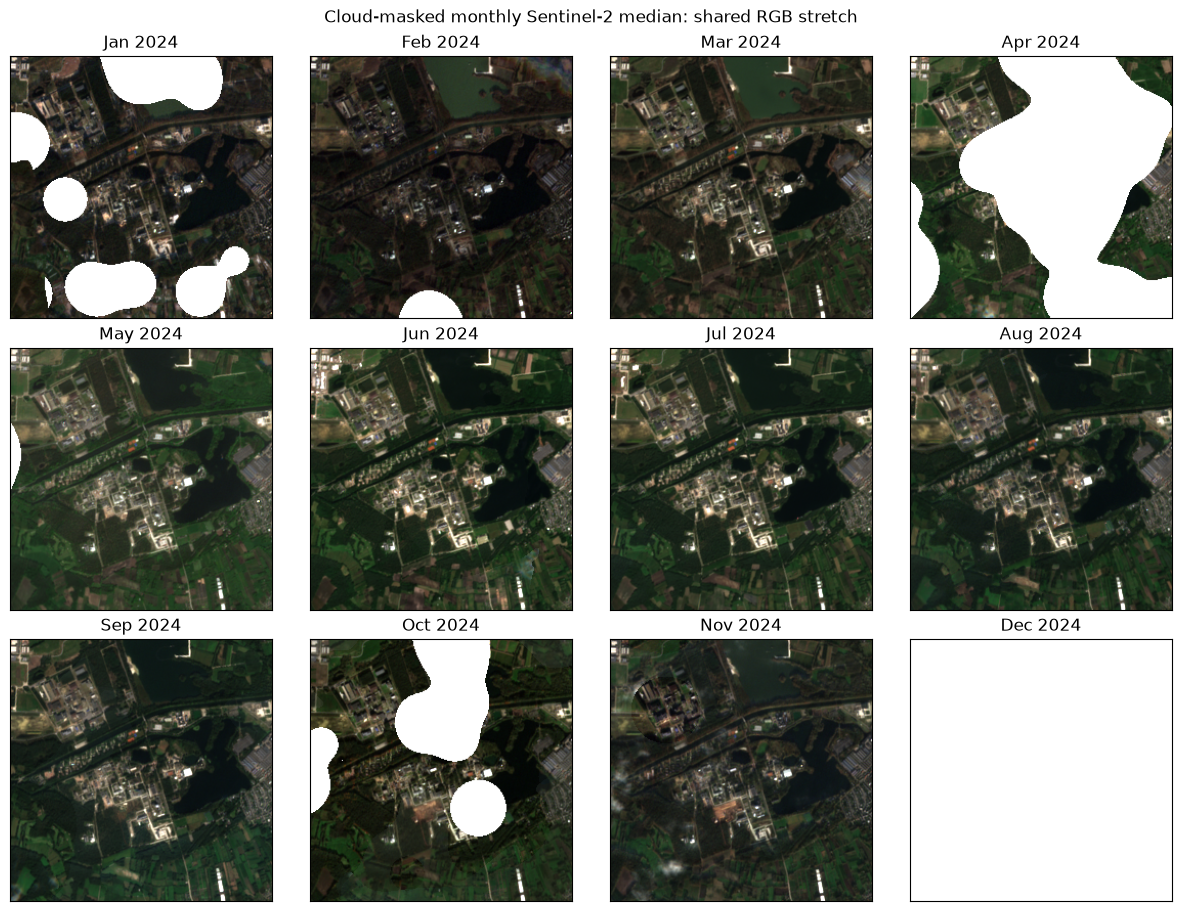

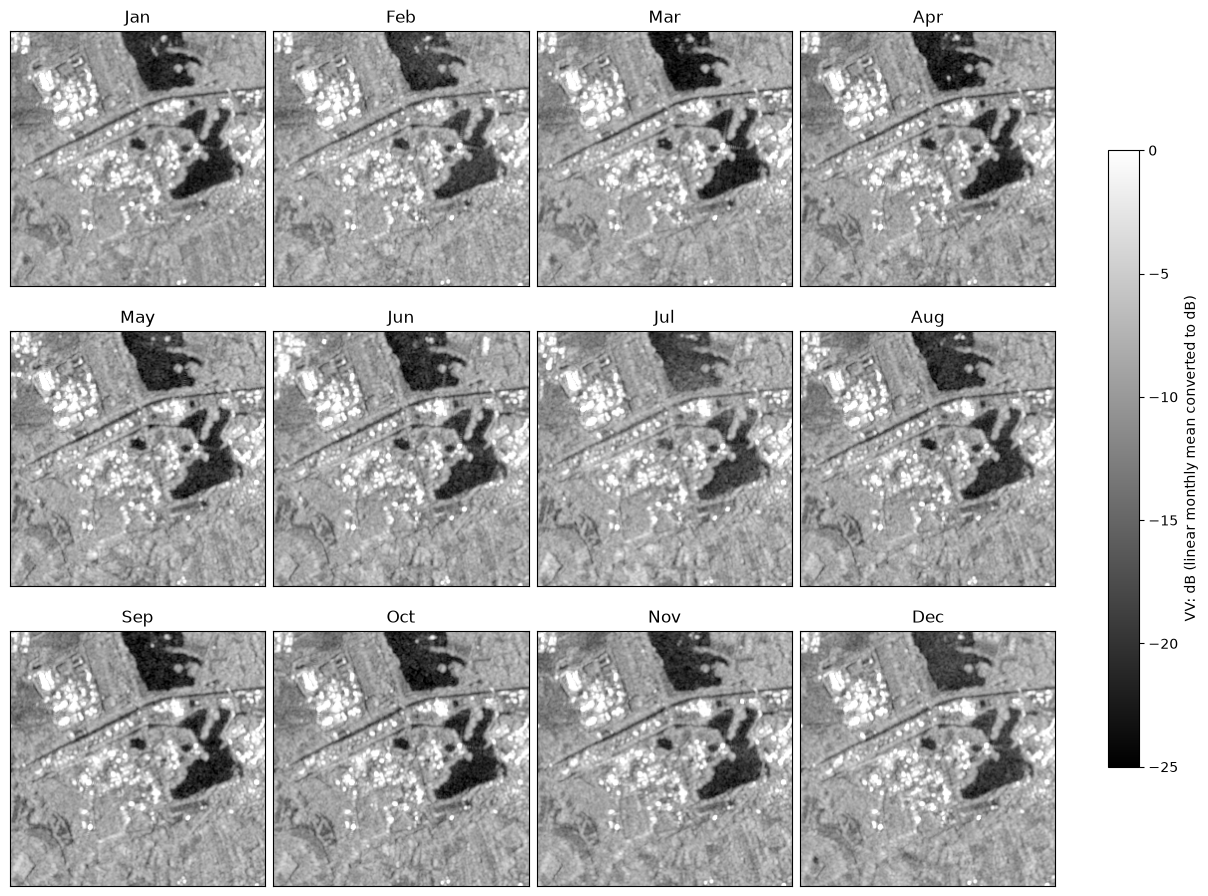

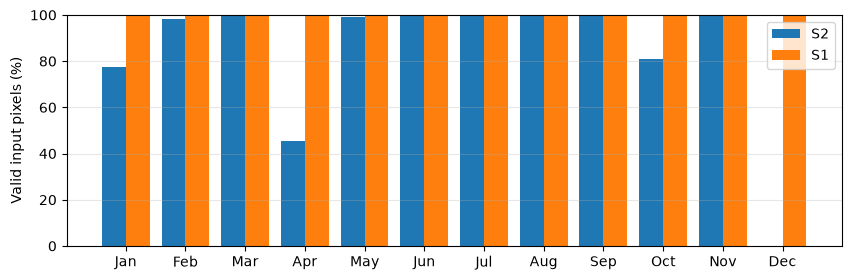

In [12]:
month_names = [date(YEAR, m, 1).strftime('%b') for m in range(1, 13)]
fig, axes = plt.subplots(3, 4, figsize=(12, 9), constrained_layout=True)
for index, ax in enumerate(axes.flat):
    rgb = monthly[index, [2, 1, 0]].transpose(1, 2, 0) / 3000
    good = np.isfinite(rgb).all(axis=2)
    rgba = np.dstack([np.nan_to_num(np.clip(rgb, 0, 1)), good.astype(float)])
    ax.imshow(rgba, extent=[input_bounds[0], input_bounds[2], input_bounds[1], input_bounds[3]], origin='upper')
    ax.set_title(f'{month_names[index]} {YEAR}')
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle('Cloud-masked monthly Sentinel-2 median: shared RGB stretch')
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(12, 9), constrained_layout=True)
for index, ax in enumerate(axes.flat):
    image = axes.flat[index].imshow(np.ma.masked_invalid(monthly[index, 12]), cmap='gray', vmin=-25, vmax=0)
    ax.set_title(month_names[index])
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(image, ax=axes.ravel().tolist(), label='VV: dB (linear monthly mean converted to dB)', shrink=0.7)
plt.show()

optical_valid = np.isfinite(monthly[:, :12]).all(axis=1)
radar_valid = np.isfinite(monthly[:, 12:14]).all(axis=1)
coverage = np.column_stack([optical_valid.mean(axis=(1, 2)), radar_valid.mean(axis=(1, 2))]) * 100
x = np.arange(12)
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(x - 0.2, coverage[:, 0], width=0.4, label='S2')
ax.bar(x + 0.2, coverage[:, 1], width=0.4, label='S1')
ax.set_xticks(x, month_names)
ax.set_ylim(0, 100)
ax.set_ylabel('Valid input pixels (%)')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.show()


### Plot the annual features with PCA

PCA is fitted to the valid annual vectors. Its first three components form the RGB image, with each stretched between its 2nd and 98th percentiles. Similar colors show similar positions in this projection, not land-cover classes. Don't compare the colors of maps fitted with separate PCAs.

The last panel lays the 40 m cells over June's RGB image using their saved coordinates. The overlay doesn't make the features any finer.


Variance explained: [0.20143893 0.12884025 0.08240012]


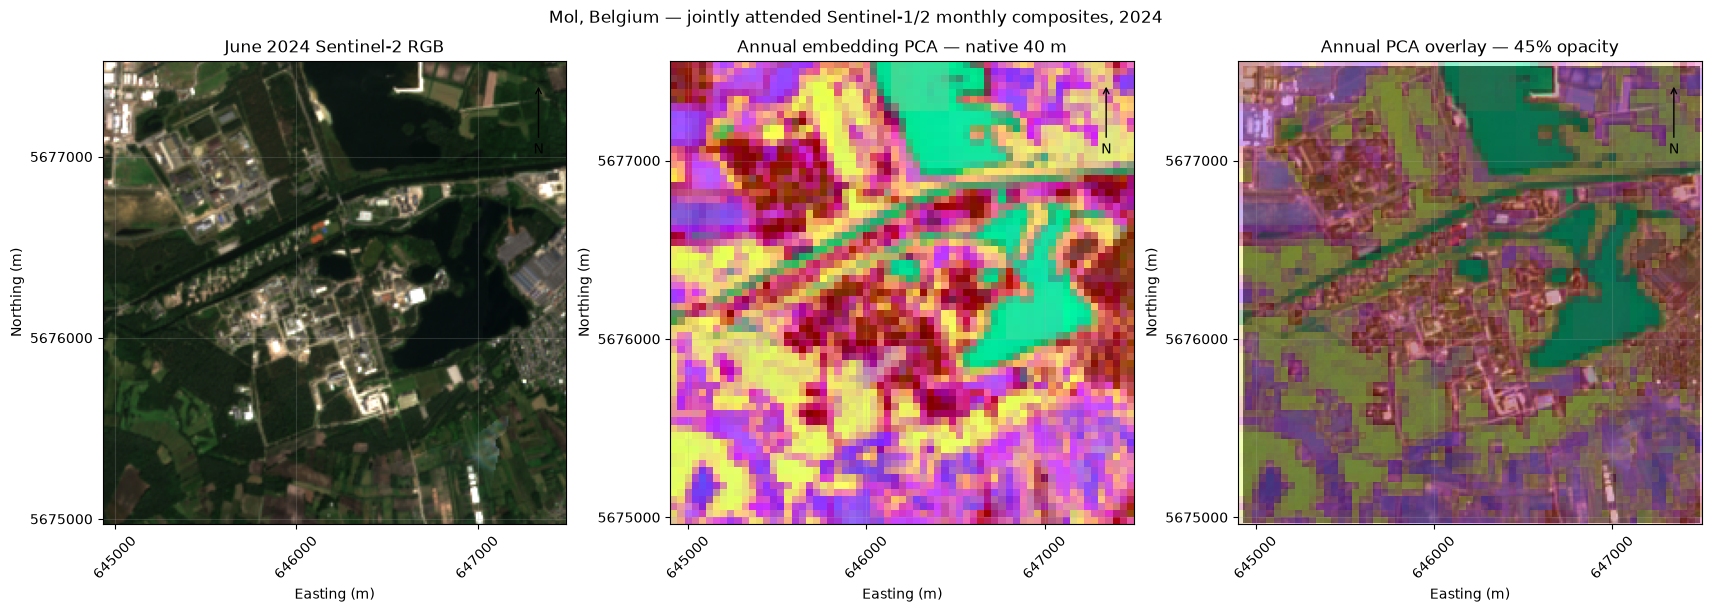

In [13]:
vectors = embeddings[:, annual_valid].T.astype(np.float64)
if len(vectors) < 4:
    raise ValueError('Need at least four valid vectors for PCA')

center = vectors.mean(axis=0)
centered = vectors - center
eigenvalues, eigenvectors = np.linalg.eigh(centered.T @ centered / (len(vectors) - 1))
components = eigenvectors[:, -3:][:, ::-1]
scores = centered @ components
lo, hi = np.percentile(scores, [2, 98], axis=0)
colors = np.clip((scores - lo) / np.maximum(hi - lo, 1e-12), 0, 1)
pca = np.zeros((*annual_valid.shape, 4), dtype=np.float32)
pca[annual_valid, :3] = colors
pca[annual_valid, 3] = 1
print('Variance explained:', eigenvalues[-3:][::-1] / eigenvalues.sum())

background = monthly[5, [2, 1, 0]].transpose(1, 2, 0) / 3000
background_valid = np.isfinite(background).all(axis=2)
background = np.dstack([np.nan_to_num(np.clip(background, 0, 1)), background_valid.astype(float)])
overlay = pca.copy()
overlay[..., 3] *= 0.45
input_extent = [input_bounds[0], input_bounds[2], input_bounds[1], input_bounds[3]]
extent = [bounds[0], bounds[2], bounds[1], bounds[3]]
fig, axes = plt.subplots(1, 3, figsize=(17, 6), constrained_layout=True)
axes[0].imshow(background, extent=input_extent, origin='upper')
axes[0].set_title(f'June {YEAR} Sentinel-2 RGB')
axes[1].imshow(pca, extent=extent, origin='upper', interpolation='nearest')
axes[1].set_title('Annual embedding PCA — native 40 m')
axes[2].imshow(background, extent=input_extent, origin='upper')
axes[2].imshow(overlay, extent=extent, origin='upper', interpolation='nearest')
axes[2].set_title('Annual PCA overlay — 45% opacity')

for ax in axes:
    ax.xaxis.set_major_locator(MultipleLocator(1000))
    ax.yaxis.set_major_locator(MultipleLocator(1000))
    ax.ticklabel_format(style='plain', useOffset=False)
    ax.tick_params(axis='x', rotation=45)
    ax.set_xlabel('Easting (m)')
    ax.set_ylabel('Northing (m)')
    ax.grid(alpha=0.2)
    ax.annotate('N', xy=(0.94, 0.95), xytext=(0.94, 0.80), xycoords='axes fraction',
                ha='center', arrowprops={'arrowstyle': '->', 'color': 'black'})
fig.suptitle(f'Mol, Belgium — jointly attended Sentinel-1/2 monthly composites, {YEAR}')
fig.savefig(folder / 'annual_embedding_pca.png', dpi=160, bbox_inches='tight')
plt.show()


## Limits

- Backend tests cover Nano on the full Mol 2024 area and all four variants on a 320 m subset. Other areas, years and months with no acquisitions at all remain untested on the backend. See [checks and limitations](./README.md#checks-and-limitations).
- Each model call sees a 320 m tile, with no overlap. It can't attend to pixels across a tile boundary, so seams are possible. A larger variant still sees the same area. Resampling coarser observations doesn't add detail.
- All months are used together. Using a full year's features to predict something partway through that year would include future observations. Missing data stays missing.
- For large areas, revisit the export and memory settings rather than copying this small example's settings unchanged.
- PCA isn't an accuracy test. Train and evaluate downstream models for the task at hand. Retrain them after switching OlmoEarth variants.
- **Licensing:** model artifacts and derivatives retain the restricted-use **[OlmoEarth Artifact License](https://huggingface.co/allenai/OlmoEarth-v1_2-Nano/blob/e1f693ae2a7d5b57871a978e9d09e22d05206747/LICENSE.txt)**. See [README](./README.md#licensing) and upstream terms before distributing weights or derived products.

Further reading: [Ai2 OlmoEarth](https://github.com/allenai/olmoearth_pretrain) and the neighbouring [TerraMind example](../terramind/terramind-embedding.ipynb).
